# ProteinBursty model demo

This notebook demonstrates the **ProteinBursty** model — a three-species extension
of the Bursty model that tracks unspliced RNA, spliced RNA, and protein jointly.

| Parameter | Symbol | Meaning |
|---|---|---|
| Burst size | *b* | Mean number of transcripts per burst |
| mRNA degradation | *β* | Degradation rate of unspliced mRNA |
| Splicing rate | *γ* | Splicing / mature mRNA degradation rate |
| Protein production | *k_p* | Translation rate |
| Protein degradation | *γ_p* | Protein degradation rate |

**Runtime:** about a minute; the two optimisations in section 5 take most of it.


In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import sys, os

import numpy as np
import matplotlib.pyplot as plt
import anndata as ad
import time

from monod.cme_toolbox import CMEModel
from monod.extract_data import extract_data

# Check which backends are active
from monod.cme_toolbox import _HAS_RUST, _HAS_GPU
os.makedirs('figures', exist_ok=True)
print(f'Rust backend: {_HAS_RUST}')
print(f'GPU  backend: {_HAS_GPU}')

Rust backend: True
GPU  backend: False


---
## 1 · Load data

The bundled `example_adata.h5ad` contains ~66 k cells with unspliced, spliced,
and **protein** layers for gene **PTPRC**.

Cells  : 65,988
Genes  : 1
Layers : ['ambiguous', 'mature', 'nascent', 'protein', 'spliced', 'unspliced']

PTPRC — mean counts:
  unspliced : 1.42  (max 71)
  spliced   : 0.62  (max 34)
  protein   : 0.20  (max 76)


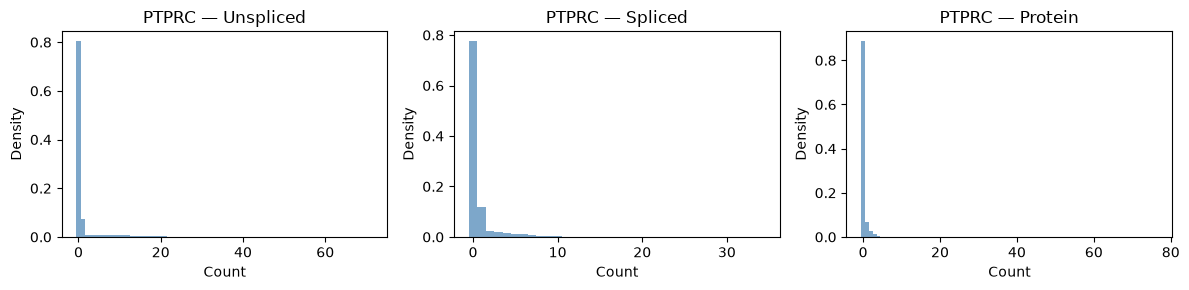

In [3]:
import scipy.sparse as sp

EXAMPLE_PATH = os.path.join('example_h5ad', 'example_adata.h5ad')
raw_adata = ad.read_h5ad(EXAMPLE_PATH)

print(f'Cells  : {raw_adata.n_obs:,}')
print(f'Genes  : {raw_adata.n_vars}')
print(f'Layers : {list(raw_adata.layers.keys())}')

def _dense(arr):
    return np.asarray(arr.todense()).ravel() if sp.issparse(arr) else np.asarray(arr).ravel()

gene = 'PTPRC'
u = _dense(raw_adata.layers['unspliced'][:, 0]).astype(int)
s = _dense(raw_adata.layers['spliced'][:, 0]).astype(int)
p = _dense(raw_adata.layers['protein'][:, 0]).astype(int)

print(f'\n{gene} — mean counts:')
print(f'  unspliced : {u.mean():.2f}  (max {u.max()})')
print(f'  spliced   : {s.mean():.2f}  (max {s.max()})')
print(f'  protein   : {p.mean():.2f}  (max {p.max()})')

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, counts, label in zip(axes, [u, s, p], ['Unspliced', 'Spliced', 'Protein']):
    ax.hist(counts, bins=np.arange(counts.max() + 2) - 0.5, density=True, color='steelblue', alpha=0.7)
    ax.set_xlabel('Count'); ax.set_ylabel('Density')
    ax.set_title(f'{gene} — {label}')
plt.savefig('figures/protein_bursty_data.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

---
## 2 · Preprocess with `extract_data`

`protein_limit=20` coarsens the protein axis of the PGF grid, reducing evaluation
time ~5× at the cost of slight approximation error.

PTPRC has low mean protein expression (< 1), so we pass `genes_to_fit` to bypass
the expression filter.

In [4]:
pb_model = CMEModel('ProteinBursty', 'None', protein_limit=20)

proc_adata = extract_data(
    raw_adata,
    pb_model,
    dataset_name='demo_protein_bursty',
    n_genes=1,
    viz=False,
    hist_type='unique',
    genes_to_fit=list(raw_adata.var_names),   # bypass expression filter
)

from monod.inference import searchdata_from_adata
from monod.extract_data import grid_limits

M3 = grid_limits(proc_adata)[:, 0].tolist()
search_data3 = searchdata_from_adata(proc_adata)
coords3, freqs3 = search_data3.hist[0]

print(f'Grid limits (unspliced, spliced, protein): {M3}')
print(f'Unique histogram points: {len(coords3)}')
print(f'Modalities: {list(proc_adata.uns["modality_name_dict"].keys())}')

Grid limits (unspliced, spliced, protein): [81, 44, 86]
Unique histogram points: 1696
Modalities: ['unspliced', 'spliced', 'protein']


---
## 3 · Method-of-Moments initial estimate

`get_MoM` uses empirical moments to compute a fast closed-form starting point.
ProteinBursty has 5 parameters: *b*, *β*, *γ*, *k_p*, *γ_p*.

In [5]:
mom3 = {col: float(proc_adata.var[col].values[0])
        for col in proc_adata.var.columns if col.startswith('MOM_')}

lb3 = np.array(pb_model.bio_bounds['phys_lb'])
ub3 = np.array(pb_model.bio_bounds['phys_ub'])

p3_mom = pb_model.get_MoM(mom3, lb3, ub3, samp=np.zeros(2))

param_names_pb = ['log₁₀ b', 'log₁₀ β', 'log₁₀ γ', 'log₁₀ k_p', 'log₁₀ γ_p']
print('MoM parameter estimates (log₁₀ scale):')
for name, val in zip(param_names_pb, p3_mom):
    print(f'  {name} = {val:.3f}  →  {10**val:.4f}')

# Evaluate PSS and KLD at MoM
t0 = time.perf_counter()
pss3_mom = pb_model.eval_model_pss(p3_mom, M3)
print(f'\nPSS evaluation time: {time.perf_counter()-t0:.2f} s')
kld3_mom = pb_model.eval_model_kld(p3_mom, M3, None, (coords3, freqs3))
print(f'KLD at MoM: {kld3_mom:.5f}')

MoM parameter estimates (log₁₀ scale):
  log₁₀ b = 1.110  →  12.8737
  log₁₀ β = 0.957  →  9.0654
  log₁₀ γ = 1.317  →  20.7365
  log₁₀ k_p = 1.359  →  22.8814
  log₁₀ γ_p = 1.847  →  70.3634

PSS evaluation time: 0.10 s
KLD at MoM: 2.10471


---
## 4 · Visualise the 3D distribution — pairwise projections

Since the PSS lives in a 3D grid (unspliced × spliced × protein), we plot
the three pairwise 2D marginals, with observed data overlaid as a scatter.

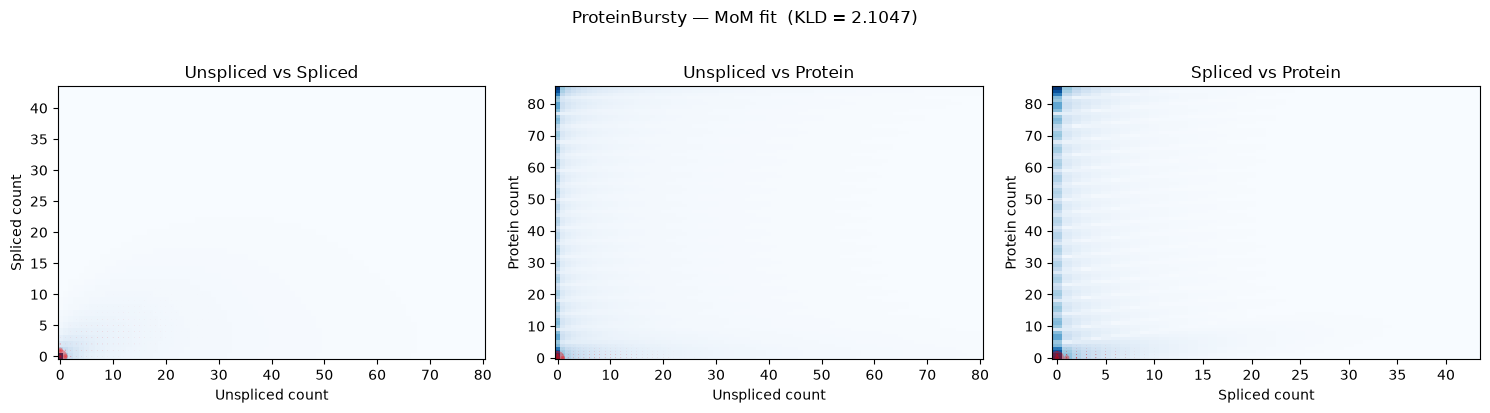

In [6]:
from monod.analysis import plot_pairwise_projections

plot_pairwise_projections(pss3_mom, M3, data=(coords3, freqs3),
                          title=f'ProteinBursty — MoM fit  (KLD = {kld3_mom:.4f})')
plt.savefig('figures/protein_bursty_pss3d_mom.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

---
## 5 · Optimisation

We minimise the KLD two ways from the same method-of-moments start:

1. **L-BFGS-B** with `eval_model_kld_and_grad`, which returns the KLD and its
   gradient in one call.  With `monod_core` installed the forward-difference
   stencil is evaluated in Rust, with every stencil point integrated on the base
   point's time grid, so the gradient is smooth in the parameters even though
   the ODE step count changes discretely with them.
2. **Nelder-Mead**, gradient-free, for comparison.

The comparison is instructive.  With protein counts coarse-grained
(`protein_limit=20`), the protein production and degradation rates
$k_p$ and $\gamma_p$ are only weakly identified individually: the likelihood
has a long, nearly flat valley along which they trade off, and both
optimisers move the pair together by one to one and a half decades while
the other three parameters barely change.  Since the steady state is
integrated with an error-controlled exponential scheme, the objective is
smooth enough for L-BFGS-B to follow the valley to its floor (KLD 2.0698
here); Nelder-Mead, capped at 100 iterations, stops part of the way.  On
simulated data with known parameters the picture is the reverse in the
regimes where protein and mRNA turnover are comparable: there the
finite-difference gradient stalls on the plateau and Nelder-Mead does not.
Random restarts do not help in either case: they reach the same optimum at
50 to 300 times the cost.  For this reason `InferenceParameters` fits the
protein model in two stages by default: a Nelder-Mead pre-search from the
moments estimate, then the L-BFGS-B polish (`gradient_params["presearch"]`,
see the [usage docs](../docs/usage.md#a-note-on-the-protein-model)).


In [7]:
from scipy.optimize import minimize

M3_list = [int(m) for m in M3]
data3 = (coords3, freqs3)
bounds3 = list(zip(lb3, ub3))
n3_evals = {'lbfgsb': 0, 'nm': 0}

def kld_and_grad(p_log, key):
    n3_evals[key] += 1
    return pb_model.eval_model_kld_and_grad(p_log, M3_list, None, data3)

def kld_only(p_log):
    n3_evals['nm'] += 1
    return pb_model.eval_model_kld(p_log, M3_list, None, data3)

opts_lbfgsb = {'maxiter': 200, 'ftol': 1e-10, 'gtol': 1e-6}

t0 = time.perf_counter()
res_lb = minimize(kld_and_grad, x0=p3_mom, args=('lbfgsb',), jac=True,
                  method='L-BFGS-B', bounds=bounds3, options=opts_lbfgsb)
t_lb = time.perf_counter() - t0

t0 = time.perf_counter()
res_nm = minimize(kld_only, x0=p3_mom, method='Nelder-Mead',
                  options={'maxiter': 100, 'xatol': 1e-3, 'fatol': 1e-4})
t_nm = time.perf_counter() - t0

print(f'{"stage":28s} {"KLD":>9s}  {"evals":>6s}  {"time":>6s}')
print(f'{"L-BFGS-B from MoM":28s} {res_lb.fun:9.5f}  {n3_evals["lbfgsb"]:6d}  {t_lb:5.1f}s   ({res_lb.nit} iterations)')
print(f'{"Nelder-Mead from MoM":28s} {res_nm.fun:9.5f}  {n3_evals["nm"]:6d}  {t_nm:5.1f}s')

best = min((res_lb, res_nm), key=lambda r: r.fun)
p3_opt, kld3_opt = best.x, best.fun

print(f'\nParameter comparison (log10 scale), best stage:')
for name, vm, vo in zip(param_names_pb, p3_mom, p3_opt):
    print(f'  {name:12s}: MoM = {vm:.3f}  ->  opt = {vo:.3f}  (delta = {vo-vm:+.3f})')
print(f'\nKLD  MoM -> opt:  {kld3_mom:.5f}  ->  {kld3_opt:.5f}'
      f'  (improvement {kld3_mom-kld3_opt:.5f})')


stage                              KLD   evals    time
L-BFGS-B from MoM              2.06976      72   31.5s   (35 iterations)
Nelder-Mead from MoM           2.08359     157   14.3s

Parameter comparison (log10 scale), best stage:
  log₁₀ b     : MoM = 1.110  ->  opt = 1.104  (delta = -0.005)
  log₁₀ β     : MoM = 0.957  ->  opt = 0.887  (delta = -0.071)
  log₁₀ γ     : MoM = 1.317  ->  opt = 1.198  (delta = -0.119)
  log₁₀ k_p   : MoM = 1.359  ->  opt = 0.381  (delta = -0.978)
  log₁₀ γ_p   : MoM = 1.847  ->  opt = 0.346  (delta = -1.502)

KLD  MoM -> opt:  2.10471  ->  2.06976  (improvement 0.03495)


---
## 6 · Visualise the optimised fit

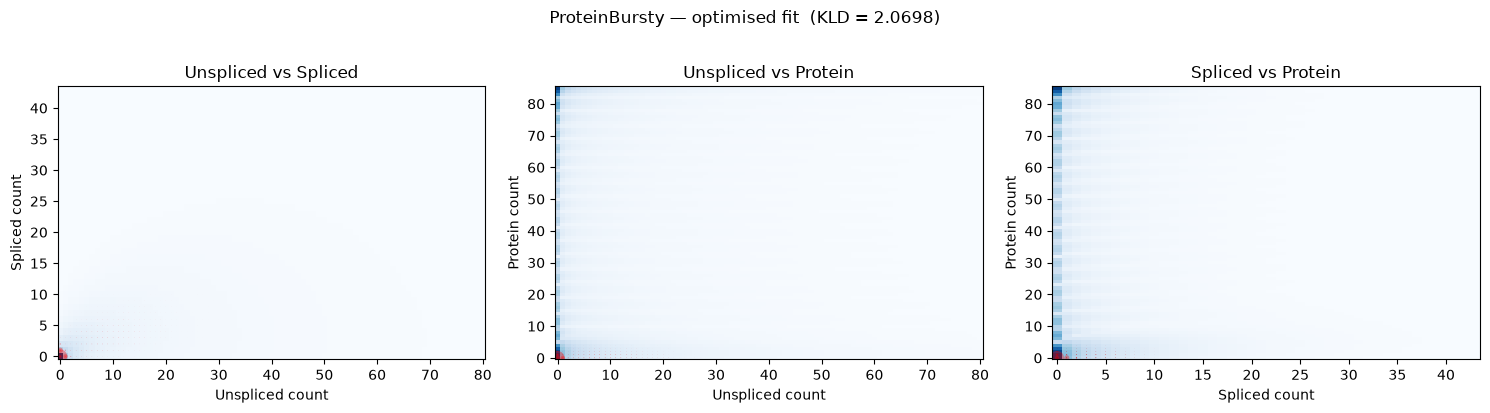

In [8]:
pss3_opt = pb_model.eval_model_pss(p3_opt, M3)
plot_pairwise_projections(pss3_opt, M3, data=(coords3, freqs3),
                          title=f'ProteinBursty — optimised fit  (KLD = {kld3_opt:.4f})')
plt.savefig('figures/protein_bursty_pss3d.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

---
## 7 · MoM vs optimised — marginal comparison

Plot all three marginals side-by-side to see where the optimiser improved the fit.

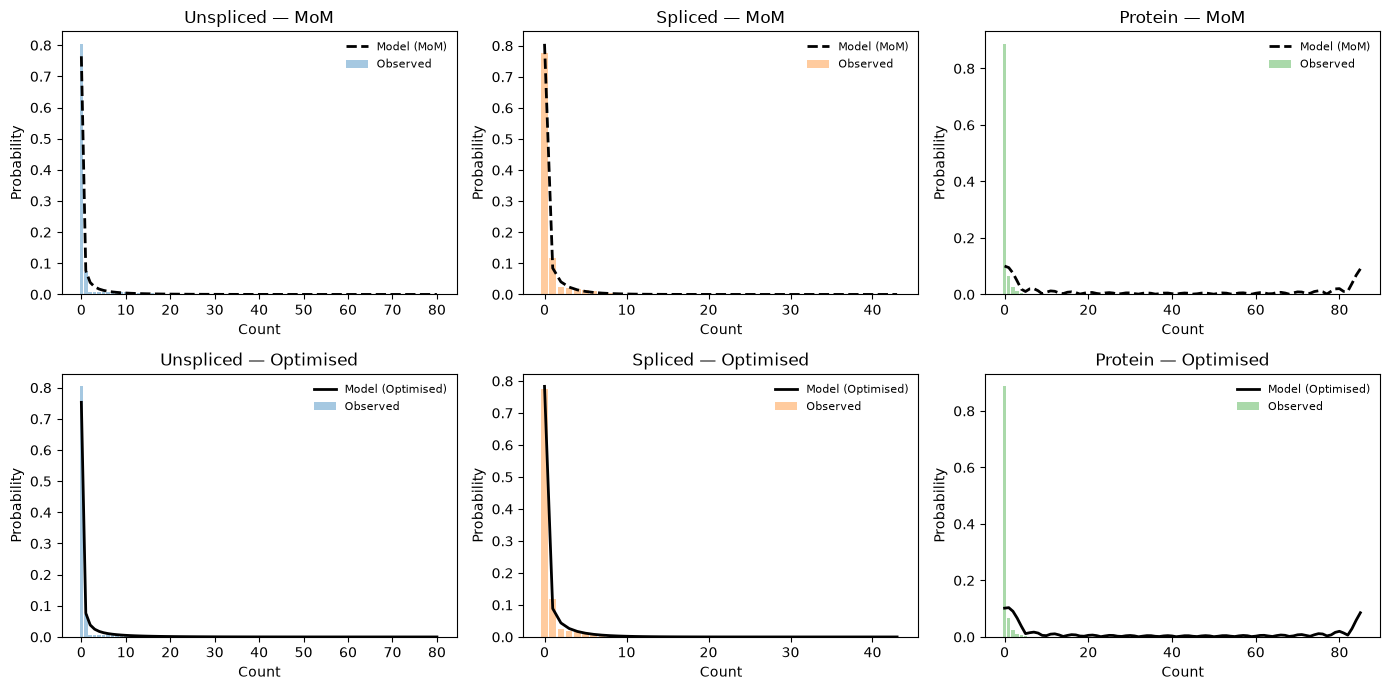

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
modality_labels = ['Unspliced', 'Spliced', 'Protein']
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Empirical marginals from the unique histogram
obs_marg = [np.zeros(M3[d]) for d in range(3)]
for pt, f in zip(coords3, freqs3):
    for d in range(3):
        if int(pt[d]) < M3[d]:
            obs_marg[d][int(pt[d])] += f

for col, (label, color) in enumerate(zip(modality_labels, colors)):
    obs = obs_marg[col]
    # sum over the other two axes
    pss_m_mom = pss3_mom.sum(axis=tuple(d for d in range(3) if d != col))
    pss_m_opt = pss3_opt.sum(axis=tuple(d for d in range(3) if d != col))

    for row, (ax, pss_m, fit_label, ls) in enumerate(zip(
            axes[:, col],
            [pss_m_mom, pss_m_opt],
            ['MoM', 'Optimised'],
            ['--', '-'])):
        ax.bar(np.arange(len(obs)), obs, color=color, alpha=0.4, label='Observed')
        ax.plot(np.arange(len(pss_m)), pss_m, 'k', lw=2,
                linestyle=ls, label=f'Model ({fit_label})')
        ax.set_xlabel('Count'); ax.set_ylabel('Probability')
        ax.set_title(f'{label} — {fit_label}')
        ax.legend(frameon=False, fontsize=8)

plt.savefig('figures/protein_bursty_fit.png', dpi=150, bbox_inches='tight')
plt.tight_layout(); plt.show()

---
## 8 · Fitted parameter interpretation

In [10]:
print('Fitted ProteinBursty parameters for PTPRC:')
print()
for name, val_log in zip(param_names_pb, p3_opt):
    val = 10**val_log
    print(f'  {name} = {val_log:.3f}  →  {val:.4f}')

b, beta, gamma, k_p, gamma_p = 10**p3_opt
print(f'\nDerived quantities:')
print(f'  Mean burst size          b       = {b:.2f}')
print(f'  mRNA half-life     ln2/β  = {np.log(2)/beta:.2f} a.u.')
print(f'  Splicing half-life  ln2/γ  = {np.log(2)/gamma:.2f} a.u.')
print(f'  Protein production rate k_p     = {k_p:.2f}')
print(f'  Protein half-life  ln2/γ_p= {np.log(2)/gamma_p:.2f} a.u.')
print(f'  Mean mRNA   ≈ b·β/(β·γ)       = {b*beta/(beta*gamma):.2f}')
print(f'  Mean protein ≈ k_p/γ_p        = {k_p/gamma_p:.2f}')

Fitted ProteinBursty parameters for PTPRC:

  log₁₀ b = 1.104  →  12.7157
  log₁₀ β = 0.887  →  7.7007
  log₁₀ γ = 1.198  →  15.7802
  log₁₀ k_p = 0.381  →  2.4069
  log₁₀ γ_p = 0.346  →  2.2159

Derived quantities:
  Mean burst size          b       = 12.72
  mRNA half-life     ln2/β  = 0.09 a.u.
  Splicing half-life  ln2/γ  = 0.04 a.u.
  Protein production rate k_p     = 2.41
  Protein half-life  ln2/γ_p= 0.31 a.u.
  Mean mRNA   ≈ b·β/(β·γ)       = 0.81
  Mean protein ≈ k_p/γ_p        = 1.09
